## Install dataset dependencies and imports


In [ ]:
!pip install medmnist

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 87 kB 3.9 MB/s 
  Created wheel for fire: filename=fire-0.4.0-py2.py3-none-any.whl size=115940 sha256=93fb12fc3b6c54caccbab41bef47348bfaa3fb00601588a31d11aa2b59ef8375
  Stored in directory: /root/.cache/pip/wheels/8a/67/fb/2e8a12fa16661b9d5af1f654bd199366799740a85c64981226
Successfully built fire


In [ ]:
from tqdm import tqdm
import numpy as np
import os

import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data
import torch.nn.functional as F

import torchvision.transforms as transforms
import torchvision.utils as vutils
from torchvision import datasets

import medmnist
from medmnist import INFO, Evaluator

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
print(f"MedMNIST v{medmnist.__version__} @ {medmnist.HOMEPAGE}")

MedMNIST v2.1.0 @ https://github.com/MedMNIST/MedMNIST/


## Configuración del conjunto de datos y el iterador sobre los datos


In [ ]:
# Initialize dataset parameters
data_flag = 'organamnist' # Which dataset to use
download = True
info = INFO[data_flag]
DataClass = getattr(medmnist, info['python_class'])

In [ ]:
BATCH_SIZE = 100
IMAGE_SIZE = 28

# Transformaciones
data_transform = transforms.Compose([
    transforms.Resize([IMAGE_SIZE, IMAGE_SIZE]),
    transforms.ToTensor(),
    transforms.Normalize(mean=[.5], std=[.5])
])

# Conjunto de datos
training_dataset = DataClass(split='train', transform=data_transform, download=download)
print(training_dataset)

# Iterador sobre los datos
training_loader = torch.utils.data.DataLoader(dataset=training_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

  0%|          | 0/38247903 [00:00<?, ?it/s]

Dataset OrganAMNIST (organamnist)
    Number of datapoints: 34581
    Root location: /root/.medmnist
    Split: train
    Task: multi-class
    Number of channels: 1
    Meaning of labels: {'0': 'bladder', '1': 'femur-left', '2': 'femur-right', '3': 'heart', '4': 'kidney-left', '5': 'kidney-right', '6': 'liver', '7': 'lung-left', '8': 'lung-right', '9': 'pancreas', '10': 'spleen'}
    Number of samples: {'train': 34581, 'val': 6491, 'test': 17778}
    Description: The OrganAMNIST is based on 3D computed tomography (CT) images from Liver Tumor Segmentation Benchmark (LiTS). It is renamed from OrganMNIST_Axial (in MedMNIST v1) for simplicity. We use bounding-box annotations of 11 body organs from another study to obtain the organ labels. Hounsfield-Unit (HU) of the 3D images are transformed into gray-scale with an abdominal window. We crop 2D images from the center slices of the 3D bounding boxes in axial views (planes). The images are resized into 1×28×28 to perform multi-class classifi

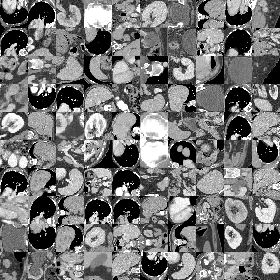

In [ ]:
# Mostramos una muestra de los datos
training_dataset.montage(length=10)

## Configuración de los principales parámetros del entrenamiento

1. Definir el número de épocas de entrenamiento (EPOCHS) --> 60
2. Definir el tamaño del vector z (Z_DIM) --> 1000
3. Se empleará el método de optimización de parámetros Adam con LEARNING_RATE = 0.0002, ADAM_BETAS = (0.5, 0.999) y WHEIGHT_DECAY = 2e-5
4. Definir la función de coste/error más adecuada para el entrenamiento de GANs (loss_fn).
5. El número de clases NUM_CLASSES = 11.
6. La salida del embedding que modela las etiquetas de las clases LABEL_EMBED_SIZE = 7.


## Funciones auxiliares

In [ ]:
# Directories for storing models and output samples
model_path = os.path.join('./model')
os.makedirs(model_path, exist_ok=True)
samples_path = os.path.join('./samples')
os.makedirs(samples_path, exist_ok=True)

In [ ]:
# Method for storing generated images
def generate_imgs(z, gen, fixed_label, epoch=0):
    gen.eval()
    fake_imgs = gen(z, fixed_label)
    fake_imgs = (fake_imgs + 1) / 2
    fake_imgs = fake_imgs[:,None,:, :] # Workaround
    fake_imgs_ = vutils.make_grid(fake_imgs, normalize=True, nrow=IMGS_TO_DISPLAY_PER_CLASS)
    vutils.save_image(fake_imgs_, os.path.join(samples_path, 'sample_' + str(epoch) + '.png'))

## Definiciones de los modelos

### Definición del generador
Se tiene que completar el código que se muestra a continuación para construir un generador. Emplear la API `Sequential`.

El generador tendrá cinco modulos definidos por una capa `nn.Linear()` y la función de activación `nn.LeakyReLU(0.2, inplace=True)`. Los módulos `nn.Linear()` tendrán las siguientes neuronas de entrada y salida.
* Capa 1 --> Entrada: necesaria para que entre el vector del espacio latente y la lectura de las etiquetas y Salida: 256.
* Capa 2 --> Entrada: necesaria para conectar con la capa anterior y Salida: 512.
* Capa 3 --> Entrada: necesaria para conectar con la capa anterior y Salida: 1024.
* Capa 4 --> Entrada: necesaria para conectar con la capa anterior y Salida: 1024.
* Capa 5 --> Entrada: necesaria para conectar con la capa anterior y Salida: Necesaria para generar la imagen.

**Ojo:** La función de activación de la *Capa 5* no será `nn.LeakyReLU(0.2, inplace=True)`, si no la necesaria para que se genere la imagen.

Al ser un generador para una GAN condicional tendrá que manejar las etiquetas de las clases.

In [ ]:
8

SyntaxError: ignored

### Definición del Discriminador
Se tiene que completar el código que se muestra a continuación para construir un discriminador. Emplear la API `Sequential`.

El generador tendrá tres modulos definidos por una capa `nn.Linear()` y la función de activación `nn.LeakyReLU(0.2, inplace=True)`. Los módulos `nn.Linear()` tendrán las siguientes neuronas de entrada y salida.
* Capa 1 --> Entrada: necesaria para que entre las imagenes y la etiqueta y Salida: 512.
* Capa 2 --> Entrada: necesaria para conectar con la capa anterior y Salida: 256.
* Capa 3 --> Entrada: necesaria para conectar con la capa anterior y Salida: La necesaria para el cálculo de la predicción de procedencia de la imagen (real/sintética).

**Ojo:** La función de activación de la *Capa 3* no será `nn.LeakyReLU(0.2, inplace=True)`, si no la necesaria para que el discriminador dé el *feedbak* que se espera.


Al ser un discriminador para una GAN condicional tendrá que manejar las etiquetas de las clases.

In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.output_size = IMAGE_SIZE * IMAGE_SIZE #28*28

        self.label_emb = nn.Embedding(...)

        self.model = nn.Sequential(...)

    def forward(self, x, labels):
        x = x.view(x.size(0), self.output_size)
        c = self.label_emb(labels)
        c = torch.squeeze(c)
        x = torch.cat(...)
        out = self.model(x)
        return out.squeeze()

## Definición del entrenamiento

### Preparación del entrenamiento
1. Define todo lo necesario para el entrenamiento


In [ ]:
gen = Generator().to(DEVICE)
dis = Discriminator().to(DEVICE)

# Optimizadores
...

# Código auxiliar
# Vector del espacio latente para mostrar una muestra de las imágenes por clases
fixed_z = torch.randn(IMGS_TO_DISPLAY_PER_CLASS*NUM_CLASSES, Z_DIM).to(DEVICE)
fixed_label = torch.arange(0, NUM_CLASSES).to(DEVICE)
fixed_label = torch.repeat_interleave(fixed_label, IMGS_TO_DISPLAY_PER_CLASS).to(DEVICE)

# Etiquetas para la comparación
D_labels = torch.ones(BATCHSIZE, 1).to(DEVICE) # Etiquetas para Real
D_fakes = torch.zeros(BATCHSIZE, 1).to(DEVICE) # Etiquetas para Sintético

In [ ]:
total_iters = 0
# Training
for epoch in range(EPOCHS):
    gen.train()
    dis.train()

    for i, (x_real, x_label) in enumerate(data_loader):

        total_iters += 1

        # 1. Entrenamiento del Discriminador
        x_real, x_label = x_real.to(DEVICE), x_label.to(DEVICE)
        z_fake = torch.randn(BATCH_SIZE, Z_DIM).to(DEVICE)
        ....
        x_fake = gen(z_fake, x_label) # Se generan las imágenes sintéticas

        ....


        # Entrenamiento del Generador
        x_fake = gen(z_fake, x_label) # Se generan las imágenes sintéticas

        if i % 50 == 0:
            print("Epoch: " + str(epoch + 1) + "/" + str(EPOCHS)
                  + "\ttotal_iters: " + str(total_iters)
                  + "\td_loss:" + str(round(discriminator_loss.item(), 4))
                  + "\tg_loss:" + str(round(generator_loss.item(), 4))
                  )

    if (epoch + 1) % 5 == 0:
        generate_imgs(fixed_z, gen, fixed_label, epoch=epoch + 1)

generate_imgs(fixed_z, gen, fixed_label)